# Multi-head 1D CNN for ECG Folder Labels

This notebook is a cleaned and remade version of the original multi-head CNN workflow.

It expects data arranged like this:

```text
data/
  abnormal/
    file1.csv
    file2.csv
  borderline/
    file3.csv
  normal/
    file4.csv
```

The label is inferred from the folder name. The ECG parser is designed for files where the ECG signal is stored as a large list like:

```python
[[-75, 443, -586, 25, -169, 247, -69, 293], ...]
```

The uploaded sample parsed as roughly 3004 complete ECG timesteps with 8 values per timestep, so this notebook defaults to `FIXED_LENGTH = 3000` and `EXPECTED_LEADS = 8`.


In [2]:
import sys
print(sys.executable)

/Users/fahizzle/projects/github/mh-cnn-ekg/tf-env/bin/python


In [3]:
# ============================================================
# Multi-head 1D CNN for ECG files stored under class folders
# Classes are inferred from folder names:
#   data/abnormal/*.csv
#   data/borderline/*.csv
#   data/normal/*.csv
#
# Each file can contain ECG rows in this annoying form:
#   [[-75, 443, ...], [-72, 341, ...], ...]
# The loader below does NOT require the ECG array to be a clean CSV column.
# ============================================================

from pathlib import Path
from collections import Counter
import json
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow.keras import regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.layers import (
    Input, Conv1D, BatchNormalization, MaxPooling1D,
    Dropout, Dense, concatenate, GlobalAveragePooling1D
)
from tensorflow.keras.models import Model
from tensorflow.keras.utils import to_categorical

/Users/fahizzle/projects/github/mh-cnn-ekg/tf-env/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [4]:
# -----------------------------
# User settings

In [ ]:
# -----------------------------
DATA_ROOT = Path("data")   # You need to have a folder named "data" with subfolders for each class, e.g.:
#   data/abnormal/*.csv
CLASS_NAMES = ["abnormal", "borderline", "normal"]


EXPECTED_LEADS = 8
# If the real files have 12 leads, set this to 12.
# If you want the code to infer the most common row length from each file, set EXPECTED_LEADS = None.

# CNNs need every recording to have the same number of timesteps.
# The sample file yielded ~3004 complete rows, so 3000 is a safe starting point.
# Increase/decrease this if your recordings are longer/shorter.
FIXED_LENGTH = 3000

TEST_SIZE = 0.2   # fraction of full dataset, not fraction of remaining training set
VALID_SIZE = 0.2   # fraction of full dataset, not fraction of remaining training set
RANDOM_STATE = 42

BATCH_SIZE = 32
EPOCHS = 200
LEARNING_RATE = 1e-3

In [6]:
# -----------------------------
# ECG parsing utilities

In [7]:
# -----------------------------
def parse_ecg_text(text, expected_leads=EXPECTED_LEADS):
    """
    Extract ECG data from text containing rows like:
        [[-75, 443, -586, ...], [-72, 341, -582, ...], ...]

    This works even when the CSV is malformed because the ECG list contains
    unquoted commas and line breaks.

    Returns
    -------
    np.ndarray with shape (timesteps, leads)
    """
    # Grab all non-nested bracket contents. For the ECG list, this becomes one row per timestep.
    row_strings = re.findall(r"\[([^\[\]]+)\]", text, flags=re.S)

    rows = []
    for row_string in row_strings:
        nums = re.findall(r"[-+]?\d*\.?\d+(?:[eE][-+]?\d+)?", row_string)
        if len(nums) >= 2:
            rows.append([float(x) for x in nums])

    if not rows:
        raise ValueError("No ECG numeric rows were found.")

    # Infer lead count if not specified.
    if expected_leads is None:
        length_counts = Counter(len(r) for r in rows)
        expected_leads = length_counts.most_common(1)[0][0]

    # Keep only rows that match the expected number of leads.
    rows = [r for r in rows if len(r) == expected_leads]

    if not rows:
        raise ValueError(f"No ECG rows matched expected_leads={expected_leads}.")

    return np.asarray(rows, dtype=np.float32)


def load_ecg_file(path, expected_leads=EXPECTED_LEADS):
    """
    Load one ECG file.

    Handles:
    - malformed CSV/plain-text exports where the ECG array is embedded in the text
    - true .xlsx/.xls files where an 'ecg' column may contain the ECG list as a string
    """
    path = Path(path)
    suffix = path.suffix.lower()

    if suffix in [".xlsx", ".xls"]:
        df = pd.read_excel(path)

        if "ecg" in df.columns:
            text = str(df.loc[0, "ecg"])
        else:
            # Fall back: search all cells for something that looks like ECG rows.
            text = "\n".join(df.astype(str).to_numpy().ravel().tolist())
    else:
        text = path.read_text(encoding="utf-8", errors="replace")

    return parse_ecg_text(text, expected_leads=expected_leads)


def zscore_per_lead(x, eps=1e-8):
    """
    Normalize each lead within one recording.
    Shape in:  (timesteps, leads)
    Shape out: (timesteps, leads)
    """
    mean = x.mean(axis=0, keepdims=True)
    std = x.std(axis=0, keepdims=True)
    return (x - mean) / (std + eps)


def pad_or_truncate(x, fixed_length=FIXED_LENGTH):
    """
    Make every ECG recording exactly fixed_length timesteps.
    Pads short recordings with zeros at the end.
    Truncates long recordings from the beginning.
    """
    n_steps, n_leads = x.shape

    if n_steps == fixed_length:
        return x

    if n_steps > fixed_length:
        return x[:fixed_length, :]

    padded = np.zeros((fixed_length, n_leads), dtype=np.float32)
    padded[:n_steps, :] = x
    return padded


def infer_label_from_path(path, class_names=CLASS_NAMES):
    """
    Infer the label from any folder component in the path.
    Example:
        data/abnormal/file1.csv -> abnormal
        data/borderline/patient_01/file2.csv -> borderline
    """
    lower_parts = [part.lower() for part in Path(path).parts]
    matches = [label for label in class_names if label.lower() in lower_parts]

    if len(matches) == 1:
        return matches[0]

    return None


def load_dataset(
    data_root=DATA_ROOT,
    class_names=CLASS_NAMES,
    expected_leads=EXPECTED_LEADS,
    fixed_length=FIXED_LENGTH,
    file_extensions=(".csv", ".txt", ".xlsx", ".xls")
):
    """
    Load all ECG files under DATA_ROOT and use the folder name as the label.

    Returns
    -------
    X : np.ndarray, shape (samples, timesteps, leads)
    y : np.ndarray, shape (samples,)
    paths : np.ndarray, file paths used for each sample
    """
    data_root = Path(data_root)

    files = []
    for ext in file_extensions:
        files.extend(data_root.rglob(f"*{ext}"))

    X_list = []
    y_list = []
    used_paths = []
    skipped = []

    for path in sorted(files):
        label = infer_label_from_path(path, class_names)

        # Skip files not inside abnormal/borderline/normal folders.
        if label is None:
            skipped.append((str(path), "Could not infer label from folder name."))
            continue

        try:
            ecg = load_ecg_file(path, expected_leads=expected_leads)
            ecg = zscore_per_lead(ecg)
            ecg = pad_or_truncate(ecg, fixed_length=fixed_length)

            X_list.append(ecg)
            y_list.append(label)
            used_paths.append(str(path))

        except Exception as e:
            skipped.append((str(path), str(e)))

    if not X_list:
        raise RuntimeError(
            f"No usable files found under {data_root}. "
            "Expected files under folders named abnormal, borderline, and/or normal."
        )

    X = np.stack(X_list).astype(np.float32)
    y = np.asarray(y_list)
    paths = np.asarray(used_paths)

    print("Loaded X shape:", X.shape)
    print("Loaded y shape:", y.shape)
    print("\nClass counts:")
    unique, counts = np.unique(y, return_counts=True)
    for label, count in zip(unique, counts):
        print(f"  {label}: {count}")

    if skipped:
        print(f"\nSkipped {len(skipped)} file(s). First few skipped files:")
        for item in skipped[:10]:
            print(" ", item)

    return X, y, paths


def inputs_for_multi_head(X):
    """
    Convert X from shape:
        (samples, timesteps, leads)
    into a list of lead-specific arrays, each shape:
        (samples, timesteps, 1)

    This is the key format needed for the multi-head CNN.
    """
    return [X[:, :, i:i+1] for i in range(X.shape[2])]

In [8]:
# -----------------------------
# Load data

In [9]:
# -----------------------------
X, y, paths = load_dataset(DATA_ROOT)

n_samples, n_timesteps, n_leads = X.shape
print(f"\nSamples: {n_samples}")
print(f"Timesteps per sample: {n_timesteps}")
print(f"Leads / heads: {n_leads}")

Loaded X shape: (26, 3000, 8)
Loaded y shape: (26,)

Class counts:
  abnormal: 7
  borderline: 9
  normal: 10

Samples: 26
Timesteps per sample: 3000
Leads / heads: 8


In [21]:
X.shape

(26, 3000, 8)

In [10]:
# -----------------------------
# Train / validation / test split

In [11]:
# -----------------------------
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
classes = label_encoder.classes_
n_classes = len(classes)

print("\nClass encoding:")
for i, label in enumerate(classes):
    print(f"  {i}: {label}")

# First split off test set.
X_temp, X_test, y_temp, y_test, paths_temp, paths_test = train_test_split(
    X, y_encoded, paths,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_encoded
)

# Then split validation from remaining temp set.
valid_fraction_of_temp = VALID_SIZE / (1.0 - TEST_SIZE)

X_train, X_valid, y_train, y_valid, paths_train, paths_valid = train_test_split(
    X_temp, y_temp, paths_temp,
    test_size=valid_fraction_of_temp,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

print("\nSplit shapes:")
print("  X_train:", X_train.shape, "y_train:", y_train.shape)
print("  X_valid:", X_valid.shape, "y_valid:", y_valid.shape)
print("  X_test: ", X_test.shape,  "y_test: ", y_test.shape)

y_train_one_hot = to_categorical(y_train, num_classes=n_classes)
y_valid_one_hot = to_categorical(y_valid, num_classes=n_classes)
y_test_one_hot = to_categorical(y_test, num_classes=n_classes)

# Class weights help if abnormal/borderline/normal counts are uneven.
class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)
class_weights = {int(cls): float(w) for cls, w in zip(np.unique(y_train), class_weights_array)}
print("\nClass weights:", class_weights)


Class encoding:
  0: abnormal
  1: borderline
  2: normal

Split shapes:
  X_train: (18, 3000, 8) y_train: (18,)
  X_valid: (4, 3000, 8) y_valid: (4,)
  X_test:  (4, 3000, 8) y_test:  (4,)

Class weights: {0: 1.2, 1: 1.0, 2: 0.8571428571428571}


In [12]:
# -----------------------------
# Multi-head 1D CNN model

In [13]:
# -----------------------------
def build_multi_head_cnn(
    n_timesteps,
    n_leads,
    n_classes,
    learning_rate=LEARNING_RATE,
    l2_value=1e-4,
    dropout_rate=0.35
):
    inputs = []
    heads = []

    for lead_idx in range(n_leads):
        lead_input = Input(shape=(n_timesteps, 1), name=f"lead_{lead_idx + 1}_input")
        inputs.append(lead_input)

        x = Conv1D(
            filters=32,
            kernel_size=7,
            padding="same",
            activation="relu",
            kernel_regularizer=regularizers.l2(l2_value),
            name=f"lead_{lead_idx + 1}_conv1"
        )(lead_input)
        x = BatchNormalization(name=f"lead_{lead_idx + 1}_bn1")(x)
        x = MaxPooling1D(pool_size=2, name=f"lead_{lead_idx + 1}_pool1")(x)
        x = Dropout(dropout_rate, name=f"lead_{lead_idx + 1}_drop1")(x)

        x = Conv1D(
            filters=64,
            kernel_size=5,
            padding="same",
            activation="relu",
            kernel_regularizer=regularizers.l2(l2_value),
            name=f"lead_{lead_idx + 1}_conv2"
        )(x)
        x = BatchNormalization(name=f"lead_{lead_idx + 1}_bn2")(x)
        x = MaxPooling1D(pool_size=2, name=f"lead_{lead_idx + 1}_pool2")(x)
        x = Dropout(dropout_rate, name=f"lead_{lead_idx + 1}_drop2")(x)

        x = Conv1D(
            filters=128,
            kernel_size=3,
            padding="same",
            activation="relu",
            kernel_regularizer=regularizers.l2(l2_value),
            name=f"lead_{lead_idx + 1}_conv3"
        )(x)
        x = BatchNormalization(name=f"lead_{lead_idx + 1}_bn3")(x)

        # GlobalAveragePooling keeps the model smaller and safer than Flatten for long ECG traces.
        x = GlobalAveragePooling1D(name=f"lead_{lead_idx + 1}_gap")(x)
        heads.append(x)

    if len(heads) > 1:
        x = concatenate(heads, name="concatenate_lead_heads")
    else:
        x = heads[0]

    x = Dense(128, activation="relu", kernel_regularizer=regularizers.l2(l2_value), name="dense_128")(x)
    x = Dropout(0.50, name="dense_dropout_1")(x)
    x = Dense(64, activation="relu", kernel_regularizer=regularizers.l2(l2_value), name="dense_64")(x)
    x = Dropout(0.30, name="dense_dropout_2")(x)

    output = Dense(n_classes, activation="softmax", name="diagnosis_output")(x)

    model = Model(inputs=inputs, outputs=output, name="multi_head_ecg_1d_cnn")

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


model = build_multi_head_cnn(n_timesteps=n_timesteps, n_leads=n_leads, n_classes=n_classes)
model.summary()

Model: "multi_head_ecg_1d_cnn"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 lead_1_input (InputLayer)   [(None, 3000, 1)]            0         []                            
                                                                                                  
 lead_2_input (InputLayer)   [(None, 3000, 1)]            0         []                            
                                                                                                  
 lead_3_input (InputLayer)   [(None, 3000, 1)]            0         []                            
                                                                                                  
 lead_4_input (InputLayer)   [(None, 3000, 1)]            0         []                            
                                                                              

In [14]:
# -----------------------------
# Train

In [15]:
# -----------------------------
callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=25,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=8,
        min_lr=1e-6
    ),
    ModelCheckpoint(
        "best_multi_head_ecg_cnn.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    inputs_for_multi_head(X_train),
    y_train_one_hot,
    validation_data=(inputs_for_multi_head(X_valid), y_valid_one_hot),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    class_weight=class_weights,
    verbose=1
)

Epoch 1/200
1/1 [==============================] - 7s 7s/step - loss: 1.4116 - accuracy: 0.3333 - val_loss: 1.2805 - val_accuracy: 0.2500 - lr: 0.0010
Epoch 2/200
1/1 [==============================] - 0s 364ms/step - loss: 1.0229 - accuracy: 0.5556 - val_loss: 1.2843 - val_accuracy: 0.2500 - lr: 0.0010
Epoch 3/200
1/1 [==============================] - 0s 401ms/step - loss: 0.7841 - accuracy: 0.6667 - val_loss: 1.2881 - val_accuracy: 0.2500 - lr: 0.0010
Epoch 4/200
1/1 [==============================] - 0s 336ms/step - loss: 0.8130 - accuracy: 0.7778 - val_loss: 1.2912 - val_accuracy: 0.2500 - lr: 0.0010
Epoch 5/200
1/1 [==============================] - 0s 330ms/step - loss: 0.6360 - accuracy: 0.8333 - val_loss: 1.2958 - val_accuracy: 0.2500 - lr: 0.0010
Epoch 6/200
1/1 [==============================] - 0s 259ms/step - loss: 0.6484 - accuracy: 0.8333 - val_loss: 1.3029 - val_accuracy: 0.2500 - lr: 0.0010
Epoch 7/200
1/1 [==============================] - 0s 227ms/step - loss: 0.7233

In [16]:
# -----------------------------
# Evaluate


Test loss: 1.2336
Test accuracy: 0.2500
1/1 [==============================] - 0s 405ms/step

Classification report:
              precision    recall  f1-score   support

    abnormal       0.00      0.00      0.00         1
  borderline       0.00      0.00      0.00         1
      normal       0.33      0.50      0.40         2

    accuracy                           0.25         4
   macro avg       0.11      0.17      0.13         4
weighted avg       0.17      0.25      0.20         4



/Users/fahizzle/projects/github/mh-cnn-ekg/tf-env/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/fahizzle/projects/github/mh-cnn-ekg/tf-env/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/fahizzle/projects/github/mh-cnn-ekg/tf-env/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_

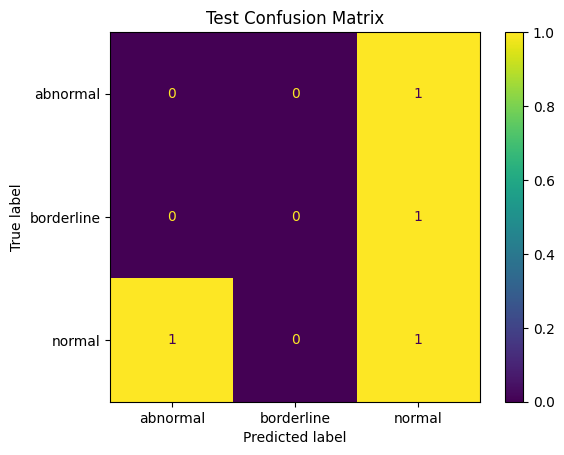

In [17]:
# -----------------------------
test_loss, test_accuracy = model.evaluate(
    inputs_for_multi_head(X_test),
    y_test_one_hot,
    verbose=0
)
print(f"\nTest loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

y_pred_prob = model.predict(inputs_for_multi_head(X_test))
y_pred = np.argmax(y_pred_prob, axis=1)

print("\nClassification report:")
print(classification_report(
    label_encoder.inverse_transform(y_test),
    label_encoder.inverse_transform(y_pred)
))

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
disp.plot(values_format="d")
plt.title("Test Confusion Matrix")
plt.show()

In [18]:
# -----------------------------
# Save final model + label metadata

In [19]:
# -----------------------------
model.save("final_multi_head_ecg_cnn.keras")

metadata = {
    "classes": classes.tolist(),
    "fixed_length": int(n_timesteps),
    "n_leads": int(n_leads),
    "expected_leads_setting": EXPECTED_LEADS,
    "normalization": "zscore_per_lead_per_recording",
    "folder_label_rule": "label inferred from a path folder named abnormal, borderline, or normal"
}

with open("ecg_cnn_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("\nSaved:")
print("  best_multi_head_ecg_cnn.keras")
print("  final_multi_head_ecg_cnn.keras")
print("  ecg_cnn_metadata.json")


Saved:
  best_multi_head_ecg_cnn.keras
  final_multi_head_ecg_cnn.keras
  ecg_cnn_metadata.json
